In [43]:
import os
import sys
from datetime import datetime
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.calibration import calibration_curve
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    roc_auc_score,
    roc_curve,
    auc,
    precision_recall_curve,
    log_loss,
    brier_score_loss,
    f1_score,
    precision_score,
    recall_score
)

# Create output directory
os.makedirs('../visualization/decision_tree', exist_ok=True)

def save_fig(name, fig=None):
    """Save figure to visualization/decision_tree directory."""
    if fig is None:
        fig = plt.gcf()
    path = f'../visualization/decision_tree/{name}.png'
    fig.savefig(path, dpi=150, bbox_inches='tight')
    print(f'  [saved {path}]')

In [44]:
# Load preprocessed train/test data from 4_preprocessing_imputation.ipynb
X_train = pd.read_csv('../data/weatherAUS_X_train.csv')
X_test = pd.read_csv('../data/weatherAUS_X_test.csv')
y_train = pd.read_csv('../data/weatherAUS_y_train.csv').squeeze()
y_test = pd.read_csv('../data/weatherAUS_y_test.csv').squeeze()

print(f'Loaded preprocessed data:')
print(f'X_train: {X_train.shape}')
print(f'X_test: {X_test.shape}')
print(f'y_train: {y_train.shape}')
print(f'y_test: {y_test.shape}')
print(f'\nData already includes:')
print(f'  - MICE imputation for missing values')
print(f'  - Cyclic encoding of wind directions (sin/cos)')
print(f'  - Categorical encoding (LabelEncoder)')
print(f'  - RobustScaler normalization')
print(f'  - Chronological train/test split (cutoff: 2016-01-01)')

Loaded preprocessed data:
X_train: (113506, 23)
X_test: (25314, 23)
y_train: (113506,)
y_test: (25314,)

Data already includes:
  - MICE imputation for missing values
  - Cyclic encoding of wind directions (sin/cos)
  - Categorical encoding (LabelEncoder)
  - RobustScaler normalization
  - Chronological train/test split (cutoff: 2016-01-01)


In [45]:
# Create evaluation split from training data (only once, at the beginning).
# This ensures: train for fitting, eval for validation, test for final testing.
from sklearn.model_selection import train_test_split

X_train_temp, X_eval, y_train_temp, y_eval = train_test_split(
    X_train, y_train,
    test_size=0.2,
    random_state=42,
    stratify=y_train
)

print(f"Split created from X_train/y_train:")
print(f"  Training set: {X_train_temp.shape}, {y_train_temp.shape}")
print(f"  Evaluation set: {X_eval.shape}, {y_eval.shape}")
print(f"  Test set: {X_test.shape}, {y_test.shape}")

# Create and train baseline Decision Tree Classifier
baseline_model = DecisionTreeClassifier(random_state=42, max_depth=5)
baseline_model.fit(X_train_temp, y_train_temp)

# Evaluate on evaluation set
y_pred_eval = baseline_model.predict(X_eval)
accuracy_eval = accuracy_score(y_eval, y_pred_eval)
report_eval = classification_report(y_eval, y_pred_eval)

print(f"\n✓ Baseline Model - Evaluation Set Results:")
print(f"Accuracy: {accuracy_eval:.4f}")
print(f"\nClassification Report:")
print(report_eval)

# Evaluate on test set
y_pred_test_baseline = baseline_model.predict(X_test)
accuracy_test_baseline = accuracy_score(y_test, y_pred_test_baseline)
report_test_baseline = classification_report(y_test, y_pred_test_baseline)

print(f"\n✓ Baseline Model - Test Set Results:")
print(f"Accuracy: {accuracy_test_baseline:.4f}")
print(f"\nClassification Report:")
print(report_test_baseline)


Split created from X_train/y_train:
  Training set: (90804, 23), (90804,)
  Evaluation set: (22702, 23), (22702,)
  Test set: (25314, 23), (25314,)

✓ Baseline Model - Evaluation Set Results:
Accuracy: 0.8442

Classification Report:
              precision    recall  f1-score   support

           0       0.85      0.97      0.91     17717
           1       0.78      0.41      0.53      4985

    accuracy                           0.84     22702
   macro avg       0.82      0.69      0.72     22702
weighted avg       0.84      0.84      0.82     22702


✓ Baseline Model - Test Set Results:
Accuracy: 0.8333

Classification Report:
              precision    recall  f1-score   support

           0       0.85      0.96      0.90     19569
           1       0.74      0.41      0.53      5745

    accuracy                           0.83     25314
   macro avg       0.79      0.68      0.71     25314
weighted avg       0.82      0.83      0.81     25314



In [46]:
from sklearn.model_selection import GridSearchCV

# Hyperparameter tuning using GridSearchCV on training split only (no leakage).
# Evaluation and test sets remain completely separate.
param_grid = {
    'max_depth': [5, 6, 7, 8, 9],
    'min_samples_split': [9, 10, 11],
    'min_samples_leaf': [3, 4, 5, 6]
}

grid_search = GridSearchCV(
    estimator=DecisionTreeClassifier(random_state=42),
    param_grid=param_grid,
    cv=5,
    scoring='roc_auc',
    n_jobs=-1,
    verbose=1
)

print("Starting GridSearchCV tuning on training split...")
grid_search.fit(X_train_temp, y_train_temp)
print("GridSearchCV complete.")

best_params = grid_search.best_params_
best_score = grid_search.best_score_
print(f"\n🎯 Best hyperparameters: {best_params}")
print(f"Best cross-validation ROC-AUC: {best_score:.4f}")

best_model = grid_search.best_estimator_

# Evaluate best model on test set only (completely unseen)
y_pred_best = best_model.predict(X_test)
y_proba_best = best_model.predict_proba(X_test)[:, 1]

accuracy_best = accuracy_score(y_test, y_pred_best)
auc_roc_best = roc_auc_score(y_test, y_proba_best)
report_best = classification_report(y_test, y_pred_best, output_dict=True, zero_division=0)

f1_best = report_best['1']['f1-score']
recall_best = report_best['1']['recall']

print(f"\n✓ Best Model - Test Set Performance:")
print(f"Accuracy: {accuracy_best:.4f}")
print(f"AUC-ROC: {auc_roc_best:.4f}")
print(f"F1 Score (Rain=Yes): {f1_best:.4f}")
print(f"Recall (Rain=Yes): {recall_best:.4f}")
print(f"\nFull Classification Report:")
print(classification_report(y_test, y_pred_best, target_names=['No Rain', 'Rain']))


Starting GridSearchCV tuning on training split...
Fitting 5 folds for each of 60 candidates, totalling 300 fits
GridSearchCV complete.

🎯 Best hyperparameters: {'max_depth': 7, 'min_samples_leaf': 6, 'min_samples_split': 9}
Best cross-validation ROC-AUC: 0.8546

✓ Best Model - Test Set Performance:
Accuracy: 0.8368
AUC-ROC: 0.8428
F1 Score (Rain=Yes): 0.5762
Recall (Rain=Yes): 0.4888

Full Classification Report:
              precision    recall  f1-score   support

     No Rain       0.86      0.94      0.90     19569
        Rain       0.70      0.49      0.58      5745

    accuracy                           0.84     25314
   macro avg       0.78      0.71      0.74     25314
weighted avg       0.83      0.84      0.83     25314



### Optimisation des hyperparamètres avec GridSearchCV

Nous allons maintenant utiliser `GridSearchCV` pour trouver les meilleurs hyperparamètres pour notre `DecisionTreeClassifier`. Cette méthode explore systématiquement toutes les combinaisons de paramètres spécifiées dans une grille et utilise la validation croisée pour évaluer la performance de chaque combinaison.

  [saved ../visualization/decision_tree/dt_calibration_curve.png]


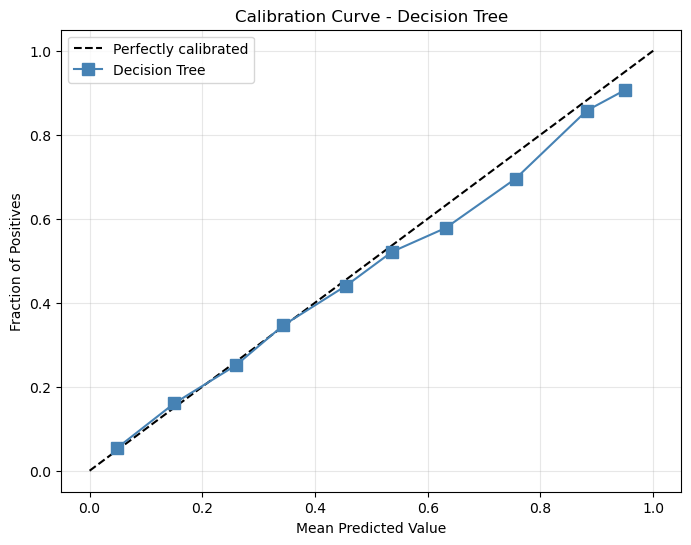

Calibration Curve saved.


In [47]:
# Calibration Curve
fop, mpv = calibration_curve(y_test, y_proba_best, n_bins=10, strategy='uniform')

fig = plt.figure(figsize=(8, 6))
plt.plot([0, 1], [0, 1], linestyle='--', label='Perfectly calibrated', color='black')
plt.plot(mpv, fop, 's-', label='Decision Tree', color='steelblue', markersize=8)
plt.xlabel('Mean Predicted Value')
plt.ylabel('Fraction of Positives')
plt.title('Calibration Curve - Decision Tree')
plt.legend(loc='upper left')
plt.grid(True, alpha=0.3)
save_fig('dt_calibration_curve')
plt.show()

print("Calibration Curve saved.")

  [saved ../visualization/decision_tree/dt_precision_recall_curve.png]


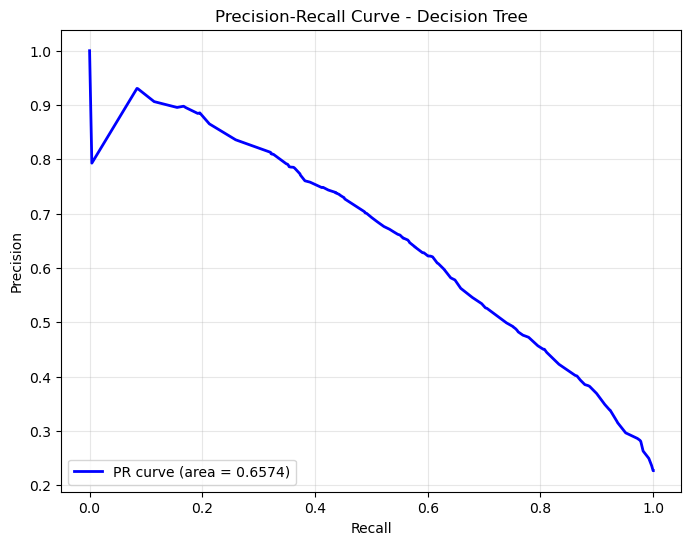

Precision-Recall Curve saved.


In [48]:
# Precision-Recall Curve
precision_curve, recall_curve, _ = precision_recall_curve(y_test, y_proba_best)
pr_auc = auc(recall_curve, precision_curve)

fig = plt.figure(figsize=(8, 6))
plt.plot(recall_curve, precision_curve, color='blue', lw=2, label=f'PR curve (area = {pr_auc:.4f})')
plt.xlabel('Recall')
plt.ylabel('Precision')
plt.title('Precision-Recall Curve - Decision Tree')
plt.legend(loc='lower left')
plt.grid(True, alpha=0.3)
save_fig('dt_precision_recall_curve')
plt.show()

print("Precision-Recall Curve saved.")

  [saved ../visualization/decision_tree/dt_roc_curve.png]


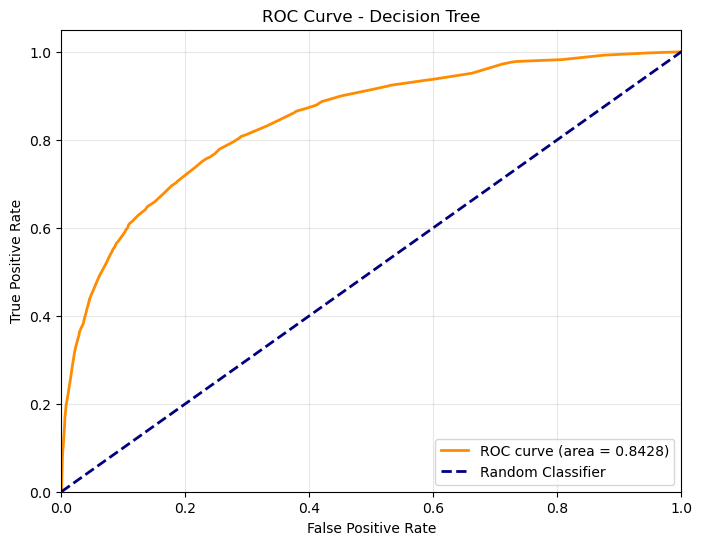

ROC Curve saved.


In [49]:
# ROC Curve
fpr, tpr, _ = roc_curve(y_test, y_proba_best)
roc_auc = auc(fpr, tpr)

fig = plt.figure(figsize=(8, 6))
plt.plot(fpr, tpr, color='darkorange', lw=2, label=f'ROC curve (area = {roc_auc:.4f})')
plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--', label='Random Classifier')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve - Decision Tree')
plt.legend(loc='lower right')
plt.grid(True, alpha=0.3)
save_fig('dt_roc_curve')
plt.show()

print("ROC Curve saved.")

  [saved ../visualization/decision_tree/dt_confusion_matrix.png]


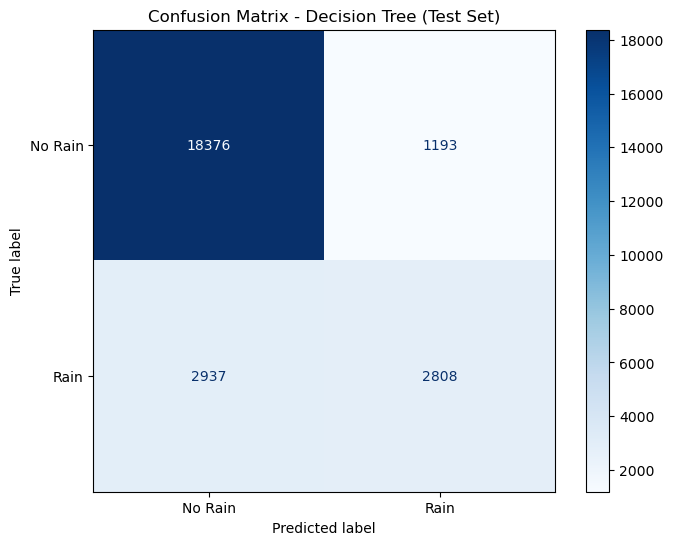

Confusion Matrix saved.


In [50]:
# Confusion Matrix
cm = confusion_matrix(y_test, y_pred_best, labels=[0, 1])
fig, ax = plt.subplots(figsize=(8, 6))
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=['No Rain', 'Rain'])
disp.plot(cmap=plt.cm.Blues, ax=ax)
plt.title('Confusion Matrix - Decision Tree (Test Set)')
save_fig('dt_confusion_matrix')
plt.show()

print("Confusion Matrix saved.")

In [51]:
# Evaluate best tuned model on evaluation set (for intermediate validation)
y_pred_eval_best = best_model.predict(X_eval)
y_proba_eval_best = best_model.predict_proba(X_eval)[:, 1]

accuracy_eval_best = accuracy_score(y_eval, y_pred_eval_best)
auc_roc_eval_best = roc_auc_score(y_eval, y_proba_eval_best)
report_eval_best = classification_report(y_eval, y_pred_eval_best, output_dict=True, zero_division=0)

print("\n✓ Best Model - Evaluation Set Performance (intermediate validation):")
print(f"Accuracy: {accuracy_eval_best:.4f}")
print(f"AUC-ROC: {auc_roc_eval_best:.4f}")
print(f"F1 Score: {report_eval_best['1']['f1-score']:.4f}")
print(f"Recall: {report_eval_best['1']['recall']:.4f}")
print(f"\nClassification Report:")
print(classification_report(y_eval, y_pred_eval_best, target_names=['No Rain', 'Rain']))



✓ Best Model - Evaluation Set Performance (intermediate validation):
Accuracy: 0.8477
AUC-ROC: 0.8630
F1 Score: 0.5860
Recall: 0.4909

Classification Report:
              precision    recall  f1-score   support

     No Rain       0.87      0.95      0.91     17717
        Rain       0.73      0.49      0.59      4985

    accuracy                           0.85     22702
   macro avg       0.80      0.72      0.75     22702
weighted avg       0.84      0.85      0.84     22702



### Decision Tree Visualization

Let's visualize the trained Decision Tree. Due to the potential complexity of the tree, only a portion might be clearly visible, but it will illustrate the decision-making process.

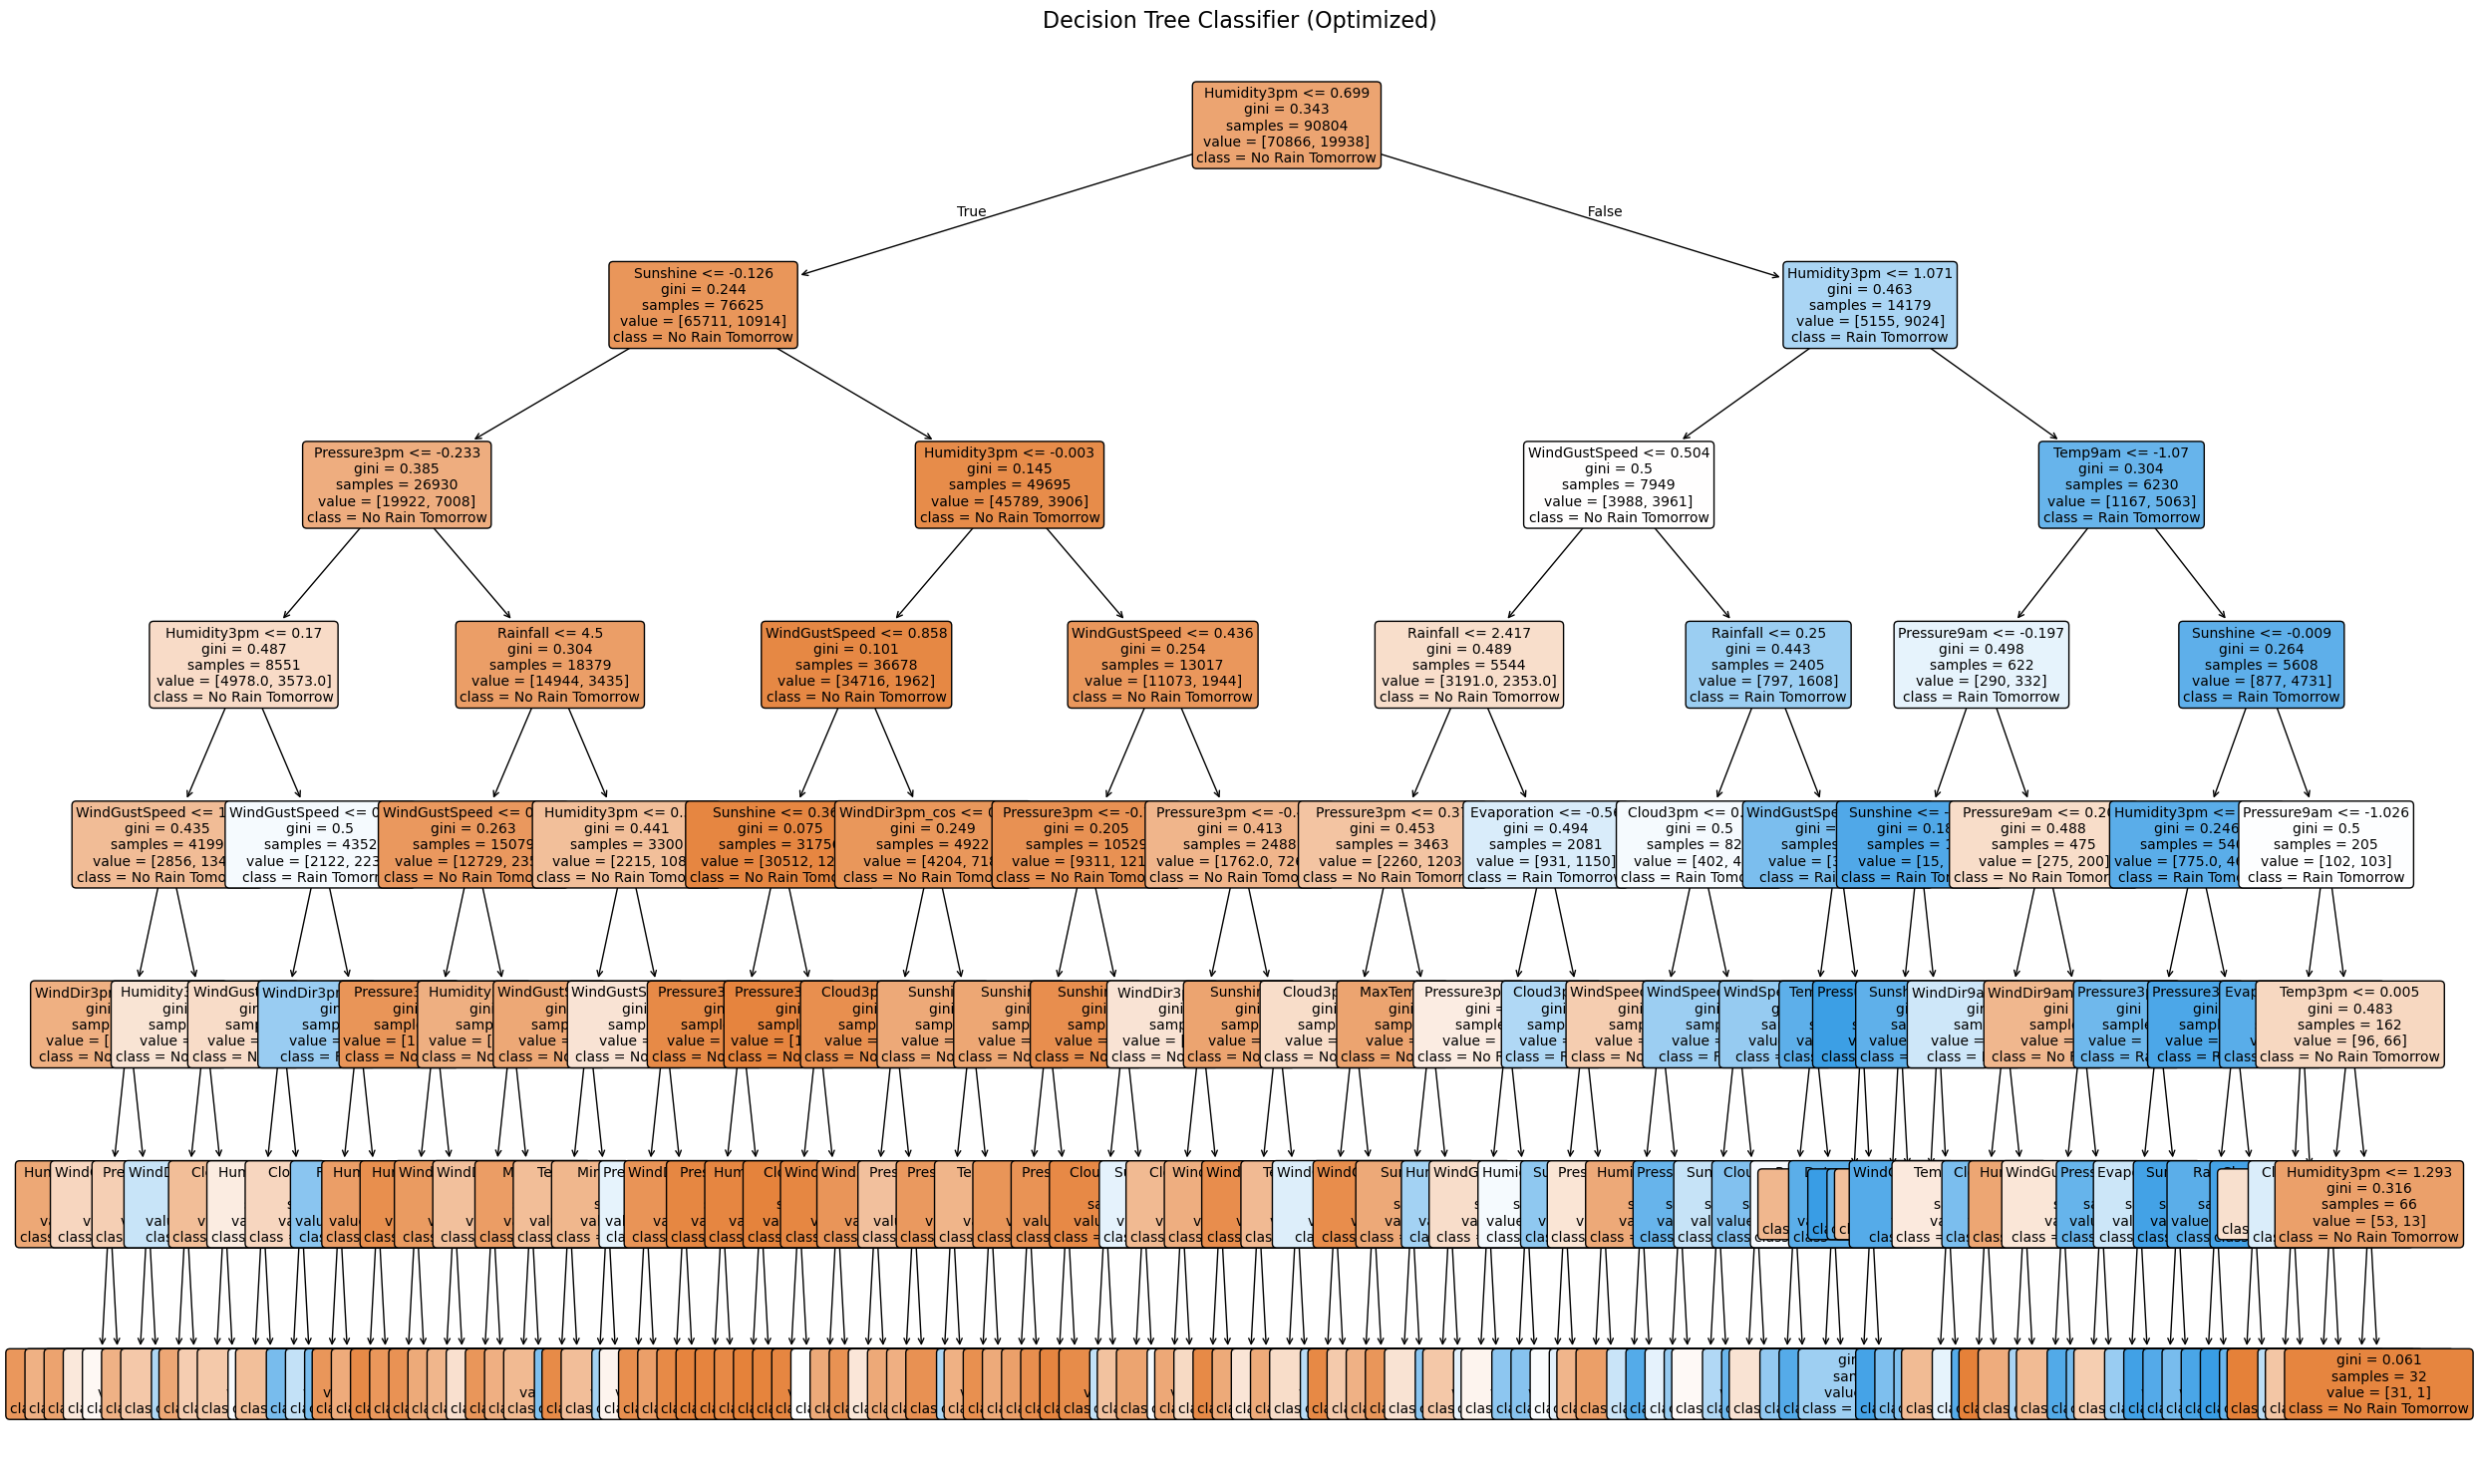

In [52]:
import matplotlib.pyplot as plt
from sklearn.tree import plot_tree

# Visualize the optimized decision tree
feature_names = X_train_temp.columns.tolist()
class_names = ['No Rain Tomorrow', 'Rain Tomorrow']

plt.figure(figsize=(25, 15))
plot_tree(
    best_model,
    feature_names=feature_names,
    class_names=class_names,
    filled=True,
    rounded=True,
    fontsize=10
)
plt.title('Decision Tree Classifier (Optimized)', fontsize=16)
plt.tight_layout()
plt.show()


In [53]:
# Install dtreeviz for interactive visualization
!pip install dtreeviz

'pip' n'est pas reconnu en tant que commande interne
ou externe, un programme ex�cutable ou un fichier de commandes.


In [54]:
# dtreeviz visualization (if available)
try:
    import dtreeviz

    feature_names = X_train_temp.columns.tolist()

    viz = dtreeviz.model(
        best_model,
        X_train=X_train_temp.values,
        y_train=y_train_temp.values,
        feature_names=feature_names,
        target_name='RainTomorrow',
        class_names=['No Rain', 'Rain']
    )
    viz.view()
except ImportError:
    print("dtreeviz not installed. Install with: pip install dtreeviz")


dtreeviz not installed. Install with: pip install dtreeviz


La location ne rentre jamais dans le decision tree

In [55]:
print("\n" + "=" * 70)
print("DECISION TREE CLASSIFIER - FINAL PERFORMANCE SUMMARY")
print("=" * 70)

# Compute all metrics for summary
precision_test = precision_score(y_test, y_pred_best)
recall_test = recall_score(y_test, y_pred_best)
f1_test = f1_score(y_test, y_pred_best)
roc_auc_test = auc_roc_best
log_loss_test = log_loss(y_test, y_proba_best)
brier_test = brier_score_loss(y_test, y_proba_best)

# Get Precision-Recall AUC
precision_test_pr, recall_test_pr, _ = precision_recall_curve(y_test, y_proba_best)
pr_auc_test = auc(recall_test_pr, precision_test_pr)

# Create summary DataFrame
summary_metrics = pd.DataFrame({
    'Metric': [
        'Accuracy',
        'Precision (Rain)',
        'Recall (Rain)',
        'F1-Score (Rain)',
        'ROC-AUC',
        'PR-AUC',
        'Log Loss',
        'Brier Score'
    ],
    'Value': [
        f'{accuracy_best:.4f}',
        f'{precision_test:.4f}',
        f'{recall_test:.4f}',
        f'{f1_test:.4f}',
        f'{roc_auc_test:.4f}',
        f'{pr_auc_test:.4f}',
        f'{log_loss_test:.4f}',
        f'{brier_test:.4f}'
    ]
})

print("\n📊 DECISION TREE CLASSIFIER - PERFORMANCE SUMMARY")
print(summary_metrics.to_string(index=False))
print("=" * 70)

# Best hyperparameters
print("\n🎯 Best Hyperparameters Found:")
print(f"   {best_params}")
print(f"   Best Cross-Validation ROC-AUC: {best_score:.4f}")

# Tree depth and complexity info
print(f"\n🌳 Model Complexity:")
print(f"   Tree Depth: {best_model.get_depth()}")
print(f"   Number of Leaves: {best_model.get_n_leaves()}")

# Save summary to CSV
summary_metrics.to_csv('../visualization/decision_tree/metrics_summary.csv', index=False)
print(f"\n✓ Metrics summary saved to: ../visualization/decision_tree/metrics_summary.csv")

# Save full report
report_dict = classification_report(y_test, y_pred_best, output_dict=True)
report_df = pd.DataFrame(report_dict).transpose()
report_df.to_csv('../visualization/decision_tree/classification_report.csv')
print(f"✓ Classification report saved to: ../visualization/decision_tree/classification_report.csv")

# List all generated files
print("\n📁 Generated Files in ../visualization/decision_tree/:")
import glob
files = glob.glob('../visualization/decision_tree/*')
for f in sorted(files):
    print(f"   - {os.path.basename(f)}")


DECISION TREE CLASSIFIER - FINAL PERFORMANCE SUMMARY

📊 DECISION TREE CLASSIFIER - PERFORMANCE SUMMARY
          Metric  Value
        Accuracy 0.8368
Precision (Rain) 0.7018
   Recall (Rain) 0.4888
 F1-Score (Rain) 0.5762
         ROC-AUC 0.8428
          PR-AUC 0.6574
        Log Loss 0.3917
     Brier Score 0.1193

🎯 Best Hyperparameters Found:
   {'max_depth': 7, 'min_samples_leaf': 6, 'min_samples_split': 9}
   Best Cross-Validation ROC-AUC: 0.8546

🌳 Model Complexity:
   Tree Depth: 7
   Number of Leaves: 123

✓ Metrics summary saved to: ../visualization/decision_tree/metrics_summary.csv
✓ Classification report saved to: ../visualization/decision_tree/classification_report.csv

📁 Generated Files in ../visualization/decision_tree/:
   - classification_report.csv
   - dt_calibration_curve.png
   - dt_confusion_matrix.png
   - dt_precision_recall_curve.png
   - dt_roc_curve.png
   - metrics_summary.csv


## Synthèse Finale - Decision Tree Classifier

Résumé complet des métriques et performances du Decision Tree Classifier optimisé